# Unsupervised Machine Learning and Time Series Forecasting of Alphabet Inc. (GOOGL)

**Module:** Machine Learning 2 — Continuous Assessment (individual)

**Chosen domain:** Stock market — the only permitted source, Yahoo Finance, restricted to the last 10 years

**Dataset:** `data/GOOGL.csv` — daily OHLCV prices for Alphabet Inc. (GOOGL), **1 September 2016 to 29 September 2026**, 2,532 trading days, downloaded from Yahoo Finance with the `yfinance` package

## Introduction, motivation, problem domain, assessment objectives and the rationale for the chosen dataset

### Introduction

This assessment applies **unsupervised machine learning** and **time series forecasting** to ten years of
daily share prices for Alphabet Inc. (GOOGL), the parent company of Google. There are two parts:

1. **Clustering.** A share does not behave the same way every day. Some days are quiet, others are wild.
   Nobody gives us labels for these "market regimes", so finding them is an **unsupervised** problem. We
   group the trading days using two clustering algorithms - **K-Means** and **K-Medoids** - and compare
   what they find.
2. **Time series forecasting.** We then treat the closing price as a time series, look for trend,
   seasonality and anomalies, build an **ARIMA** model, extend it to a seasonal **SARIMA** model, and check
   whether either one can forecast better than a very simple guess.

### Motivation

* **Risk management.** A 2% fall means something different on a calm day than on a panic day. If we can put
  each day into a regime, we can change how much risk we take.
* **Forecasting.** Investors want to know the future price *and* how uncertain it is. ARIMA gives both a
  prediction and a confidence interval. If the model cannot beat a simple guess, that is also a useful
  answer — it supports the **efficient market hypothesis** (Fama, 1970).

### Description of the problem domain

The domain is the **stock market**. Every trading day the exchange gives us six numbers:

| Variable | Meaning |
|---|---|
| `Open` | Price of the first trade of the day |
| `High` | Highest price during the day |
| `Low` | Lowest price during the day |
| `Close` | Price of the last trade of the day |
| `Adj Close` | Close adjusted for splits and dividends — the correct one for returns |
| `Volume` | Number of shares traded |

Two facts about share prices shape everything we do:

* **Prices are non-stationary, but returns are roughly stationary.** The price keeps trending upwards, which
  breaks the assumptions of most models. The *percentage change* behaves much better. This is why ARIMA has
  a differencing step, and why our clustering features are all percentages instead of raw prices.
* **Volatility comes in bunches.** Big moves follow big moves. That is exactly what makes "market regime" a
  sensible idea, and it is why clustering is worth trying.

### Assessment objectives

| # | Objective |
|---|---|
| **O1** | Clean the data and get at least 7 columns of mixed type (categorical, continuous, discrete) |
| **O2** | Choose clustering algorithms, explain why, implement two of them and compare |
| **O3** | Measure **similarity/dissimilarity between clusters** |
| **O4** | Explain the difference between **silhouette score** and **Davies–Bouldin index**, and say which solution we prefer |
| **O5** | Explore the time series for **trend, seasonality and anomalies** |
| **O6** | Find the ARIMA parameters **(p, d, q)**, evaluate the forecast, give strengths and limitations |

### Questions we ask about this dataset

* **Q1.** Which clustering solution do we prefer, and why?
* **Q2.** Can ARIMA or SARIMA beat a simple guess?

### Why this dataset was chosen

1. **It follows the rules.** It comes from Yahoo Finance and covers exactly ten years, as the brief requires.
2. **It is big enough.** 2,532 trading days is plenty of rows for clustering and for ARIMA.
3. **The regimes really exist.** These ten years include the 2018 tech selloff, the COVID crash of 2020, the
   2021 boom, the 2022 fall (GOOGL lost 39.1% that year) and the 2023–2026 AI rally. Clustering only makes
   sense if the data really contains different behaviours, and this period does.
4. **The data is clean.** Alphabet is a huge company that trades every day, so there are no missing days and
   no strange values to argue about.
5. **We can build mixed variable types.** From the six raw columns we can make continuous, discrete and
   categorical variables, as the brief requires.
6. **It supports both parts of the assignment.** The same daily prices feed the clustering analysis (regimes from returns, volatility and volume) and the time series analysis (trend, ARIMA and SARIMA forecasting), so one dataset answers both sets of questions.

```Import Libraries```

In [3]:
# Suppress the warnings so the output is easier to read
import warnings
warnings.filterwarnings('ignore')

# Libraries for arrays, dataframes and plotting
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib

# Scaling and encoding
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import LabelEncoder

# Clustering algorithms - the two we compare, plus DBSCAN which we test and reject in 7.8
from sklearn.cluster import KMeans
from pyclustering.cluster.kmedoids import kmedoids
from sklearn.cluster import DBSCAN

# Scores to measure how good the clusters are
from sklearn.metrics import silhouette_score
from sklearn.metrics import silhouette_samples
from sklearn.metrics import davies_bouldin_score
from sklearn.metrics import adjusted_rand_score

# For the distance matrix that K-Medoids needs
from scipy.spatial.distance import pdist, squareform
from sklearn.neighbors import NearestNeighbors
from sklearn.decomposition import PCA

# Time series libraries
import statsmodels.api as sm
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.stattools import kpss
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.stats.diagnostic import acorr_ljungbox

# Error measures for the forecasts
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

from scipy import stats

print('All libraries imported successfully.')

All libraries imported successfully.


```Loading data```

The data was downloaded once from Yahoo Finance using the `yfinance` package and saved into
`data/GOOGL.csv`, so the notebook always uses the same data:

```python
import yfinance as yf
df = yf.download("GOOGL", start="2016-09-01", end="2026-09-30", auto_adjust=False)
df.to_csv("data/GOOGL.csv")
```

We use `auto_adjust=False` so that the **`Adj Close`** column is kept. `Adj Close` is the price adjusted for
splits and dividends, and it is the correct column for calculating returns.

The file that `yfinance` writes has **three header rows** instead of one, so we skip the first 3 rows and
give the column names ourselves.

In [1]:
# Getting 10 years daily Dataset of Apple from Yahoo Finanace

# os.makedirs("data", exist_ok=True)

# auto_adjust=False keeps the "Adj Close" column, as in your file

# df = yf.download("GOOGL", start="2016-09-01", end="2026-09-30", auto_adjust=False)
# df.to_csv("data/GOOGL.csv")
# df.head()

In [4]:
# The yfinance file has 3 header rows, so skip them and name the columns ourselves
cols = ['Date', 'Adj Close', 'Close', 'High', 'Low', 'Open', 'Volume']
df_raw = pd.read_csv('data/GOOGL.csv', skiprows=3, names=cols)

# Show the number of rows and columns
print('Rows and columns:', df_raw.shape)

# Show the first five records
df_raw.head()

Rows and columns: (2532, 7)


,Date,Adj Close,Close,High,Low,Open,Volume
0,2016-09-01,39.197018,39.570000,39.644501,39.316502,39.598999,26070000
1,2016-09-02,39.467941,39.843498,39.855000,39.662998,39.763500,26998000
2,2016-09-06,40.020184,40.401001,40.544498,39.771500,39.919498,39790000
3,2016-09-07,40.018692,40.399502,40.529999,40.186001,40.396500,22906000
4,2016-09-08,39.763615,40.141998,40.421001,40.050499,40.261002,23554000


In [5]:
# Show the data types and how many non-null values each column has
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 2532 entries, 0 to 2531
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Date       2532 non-null   str    
 1   Adj Close  2532 non-null   float64
 2   Close      2532 non-null   float64
 3   High       2532 non-null   float64
 4   Low        2532 non-null   float64
 5   Open       2532 non-null   float64
 6   Volume     2532 non-null   int64  
dtypes: float64(5), int64(1), str(1)
memory usage: 138.6 KB


### #01 Clean the data and get at least 7 columns of mixed type (categorical, continuous, discrete)

We do five checks. We **print** the result of each check first, so we can see the state of the data before
we change anything.

1. Turn `Date` into a real date and use it as the index.
2. Make sure all the price and volume columns are numbers.
3. Count the missing values.
4. Count the duplicated dates.
5. Look for impossible values, such as `High` being lower than `Low`, or a price of zero.

In [8]:
# Make a copy so the raw data is not changed
df = df_raw.copy()

# Step 1: turn the Date column into a real date and use it as the index
df['Date'] = pd.to_datetime(df['Date'], format='%Y-%m-%d')
df = df.set_index('Date')
df = df.sort_index()

# Step 2: make sure the price and volume columns are numbers
num_cols = ['Adj Close', 'Close', 'High', 'Low', 'Open', 'Volume']
for col in num_cols:
    df[col] = pd.to_numeric(df[col], errors='coerce')

df.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 2532 entries, 2016-09-01 to 2026-09-29
Data columns (total 6 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Adj Close  2532 non-null   float64
 1   Close      2532 non-null   float64
 2   High       2532 non-null   float64
 3   Low        2532 non-null   float64
 4   Open       2532 non-null   float64
 5   Volume     2532 non-null   int64  
dtypes: float64(5), int64(1)
memory usage: 138.5 KB


In [9]:
# Step 3: count the missing values in each column
print('Missing values in each column:')
print(df.isnull().sum())

# Step 4: count the duplicated dates
print('\nNumber of duplicated dates:', df.index.duplicated().sum())

# Step 5: look for impossible values
print('Rows where High is less than Low:', (df['High'] < df['Low']).sum())
print('Number of prices that are zero or negative:', (df['Close'] <= 0).sum())
print('Number of volumes that are zero or negative:', (df['Volume'] <= 0).sum())

Missing values in each column:
Adj Close    0
Close        0
High         0
Low          0
Open         0
Volume       0
dtype: int64

Number of duplicated dates: 0
Rows where High is less than Low: 0
Number of prices that are zero or negative: 0
Number of volumes that are zero or negative: 0


In [10]:
# Now remove duplicated dates and missing rows
print('Shape before cleaning:', df.shape)

df = df[~df.index.duplicated(keep='first')]
df = df.dropna()

# Volume is a count of shares, so it should be a whole number
df['Volume'] = df['Volume'].astype('int64')

print('Shape after cleaning :', df.shape)
print('First date:', df.index.min().date())
print('Last date :', df.index.max().date())

df.describe()

Shape before cleaning: (2532, 6)
Shape after cleaning : (2532, 6)
First date: 2016-09-01
Last date : 2026-09-29


,Adj Close,Close,High,Low,Open,Volume
count,2532.000000,2532.000000,2532.000000,2532.000000,2532.000000,2.532000e+03
mean,121.673956,122.479583,123.805541,121.050751,122.398992,3.374918e+07
std,82.054660,82.090928,83.068542,80.984017,82.011212,1.509569e+07
min,37.306007,37.660999,38.525002,37.179501,38.095001,9.312000e+06
25%,57.914528,58.465625,58.987375,57.902750,58.446502,2.423958e+07
50%,102.620003,103.596500,104.778500,101.930000,103.063751,3.006330e+07
75%,147.624104,148.944874,151.447495,147.825005,149.558750,3.811588e+07
max,402.121185,402.619995,408.609985,396.359985,399.920013,1.331780e+08


```Making new columns (feature engineering)```

This is the most important decision in the whole clustering part, so we explain it slowly.

### Why we cannot just cluster the raw columns

The file gives us six columns: `Open`, `High`, `Low`, `Close`, `Adj Close` and `Volume`. There are **two
separate reasons** why clustering those would fail.

**Reason 1: the price level would hide everything else.** GOOGL cost about **\$39** in 2016 and about
**\$341** in 2026. If we cluster on price, the algorithm will happily find "cheap days", "medium days" and
"expensive days" — but those are just **2017, 2021 and 2026 wearing a disguise**. The clusters would tell us
the *date*, which we already knew from the index. We would have learned nothing.

**Reason 2: the five price columns say almost the same thing.** `Open`, `High`, `Low`, `Close` and
`Adj Close` are five measurements of the same price on the same day. On a typical day they are all within
about 2% of each other. Feeding all five to a distance-based algorithm means feeding it the **same
information five times**, which silently gives "price level" five votes and `Volume` only one.

We build new columns that describe **how the market behaved** that day, expressed as **percentages**.

This is the key move. A 2% fall is a 2% fall whether the share costs \$39 or \$341. So a percentage
**throws the price level away and keeps the behaviour** — which means a day in 2017 and a day in 2026 can
land in the same cluster if they behaved alike. That is exactly what we want from a "market regime".

| New column | How we calculate it | What it tells us |
|---|---|---|
| `Return` | (today's `Adj Close` − yesterday's) / yesterday's × 100 | Which way the price moved, and by how much |
| `Log_Return` | log(today's `Adj Close` ÷ yesterday's) × 100 | The same move on a log scale — ARIMA needs this in §8 |
| `Range_Pct` | (`High` − `Low`) / `Low` × 100 | How wide the day was *inside* the day |
| `Gap_Pct` | (`Open` − yesterday's `Close`) / yesterday's `Close` × 100 | How far the price jumped **overnight**, before trading started |
| `Volatility_20` | standard deviation of `Return` over the last 20 days | How jumpy the market has been *lately* |
| `Momentum_20` | % change in `Adj Close` over the last 20 days | Whether the day sits in an uptrend or a downtrend |
| `Volume_Ratio` | `Volume` ÷ average `Volume` of the last 20 days | Was today busier than normal? (1.0 = normal) |
| `Log_Volume` | log(`Volume`) | Volume squashed onto a manageable scale |
| `Day_Of_Week` | `Mon`, `Tue`, ... taken from the date | **Categorical** — used for the day-of-week test in §8.1 |
| `Direction` | `'Up'` if `Return` >= 0, otherwise `'Down'` | **Categorical** — a simple label for the cross-tables in §7 |
| `Month_Num` | the month number, 1 to 12 | **Discrete** — used for the seasonality test in §8.1 |
| `Year` | the year, 2016 to 2026 | **Discrete** — used for grouping results by year |

That is **twelve new columns**, which added to the six raw ones gives the 18 columns we check in §5.4. The
last four exist partly because the brief asks for a mixture of variable types, and partly because we
genuinely use them in the tests later on.

**A note on the two "close" columns.** `Close` is the price as it was quoted on the day. `Adj Close` is that
price corrected for dividends, which Alphabet started paying in 2024 — so older `Adj Close` values are
slightly lower than `Close` (by up to \$1.68 in our data). We use `Adj Close` for `Return`, because it is the
honest measure of what an investor actually earned, and the quoted `Close` for `Gap_Pct`, because that is
the number the market was literally looking at when it closed.

**Why the row count will drop.** `Volatility_20`, `Momentum_20` and `Volume_Ratio` all need **20 earlier
days** of history. On day 1 there is no history at all, on day 2 there is one day, and so on — so for the
first 20 rows pandas cannot compute a value and writes `NaN` instead. We **drop** those rows rather than
filling them, because any filled value would be invented data, and because the clustering algorithms cannot
accept `NaN` at all. It costs us 20 rows out of 2,532 (**0.8%**), all at the very start, so the feature
table begins on **30 September 2016** instead of 1 September 2016.

In [ ]:
# Make a copy to add the new columns to
feat = df.copy()

# Continuous columns, all of them percentages so they do not depend on the price level

# Return is the simple percentage change in price from one day to the next
feat['Return'] = feat['Adj Close'].pct_change() * 100

# Log_Return is almost the same as Return for small moves, but not identical.
feat['Log_Return'] = np.log(feat['Adj Close'] / feat['Adj Close'].shift(1)) * 100

# Range_Pct is the gap between the day's low and high, shown as a percentage of the closing price.
feat['Range_Pct'] = (feat['High'] - feat['Low']) / feat['Low'] * 100

# Gap_Pct is the change from the previous day's close to today's opening price, as a percentage of that previous close
feat['Gap_Pct'] = (feat['Open'] - feat['Close'].shift(1)) / feat['Close'].shift(1) * 100

# Annualised 20-day volatility (%)
# Annualised volatility is the typical size of price moves over one year, expressed as a percentage.
# It takes a volatility measured over a short period, such as the daily standard deviation of returns, and scales it to a one-year figure so it can be compared with other measures and other investments.
# Example: if a stock's daily moves have a standard deviation of 1%, its annualised volatility is about 1% × √252 ≈ 15.9%.
# How to read it: if a stock has 20% annualised volatility, a rough guide is that its price might move within about ±20% over a year, about two-thirds of the time. For a single day, you divide by √252 to get the typical daily move, about 1.26% in this case.
# Investors and analysts use it to compare risk. A stock with 40% annualised volatility is usually considered much riskier than one at 15%.
feat['Volatility_20'] = feat['Return'].rolling(20).std()

# Momentum_20 measures how far today's closing price is above or below its 20-day average, as a percentage
feat['Momentum_20'] = feat['Adj Close'].pct_change(20) * 100

# Volume_Ratio compares today's trading volume with the recent average
feat['Volume_Ratio'] = feat['Volume'] / feat['Volume'].rolling(20).mean()

# Log_Volume is the natural logarithm of the day's trading volume. The notebook computes it as feat['Log_Volume'] = np.log(feat['Volume'])
feat['Log_Volume'] = np.log(feat['Volume'])

# Categorical columns
feat['Day_Of_Week'] = feat.index.day_name().str[:3]
feat['Direction'] = np.where(feat['Return'] >= 0, 'Up', 'Down')

# Discrete calendar columns
feat['Month_Num'] = feat.index.month
feat['Year'] = feat.index.year

# The first 20 rows have no 20-day values, so drop them
print('Rows before dropping the first 20 days:', feat.shape[0])
feat = feat.dropna()
print('Rows after dropping the first 20 days :', feat.shape[0])
print('Final shape:', feat.shape)

feat.head()

Rows before dropping the first 20 days: 2532
Rows after dropping the first 20 days : 2512
Final shape: (2512, 18)


,Adj Close,Close,High,Low,Open,Volume,Return,Log_Return,Range_Pct,Gap_Pct,Volatility_20,Momentum_20,Volume_Ratio,Log_Volume,Day_Of_Week,Direction,Month_Num,Year
Date,,,,,,,,,,,,,,,,,,
2016-09-30,39.824043,40.202999,40.404499,40.075001,40.180000,33204000,0.176918,0.176762,0.822204,0.119606,0.977540,1.599677,1.097969,17.318181,Fri,Up,9,2016
2016-10-03,39.641781,40.019001,40.176998,39.811501,40.127499,29784000,-0.457669,-0.458720,0.918070,-0.187798,0.973725,0.440458,0.980362,17.209482,Mon,Down,10,2016
2016-10-04,39.761143,40.139500,40.325001,39.983501,40.250000,25174000,0.301101,0.300649,0.854101,0.577223,0.921823,-0.647275,0.849045,17.041322,Tue,Up,10,2016
2016-10-05,39.683876,40.061501,40.424999,40.035500,40.299999,24276000,-0.194327,-0.194516,0.972886,0.399854,0.922539,-0.836649,0.816870,17.004999,Wed,Down,10,2016
2016-10-06,39.775509,40.153999,40.347500,40.025501,40.203999,21998000,0.230907,0.230641,0.804484,0.355698,0.913229,0.029912,0.742160,16.906462,Thu,Up,10,2016


```Exploratory Data Analysis```

Before building any model we look at the data. We make four plots:

1. the price, the volatility and the volume over time;
2. the shape of the daily returns;
3. the correlation between our new columns;

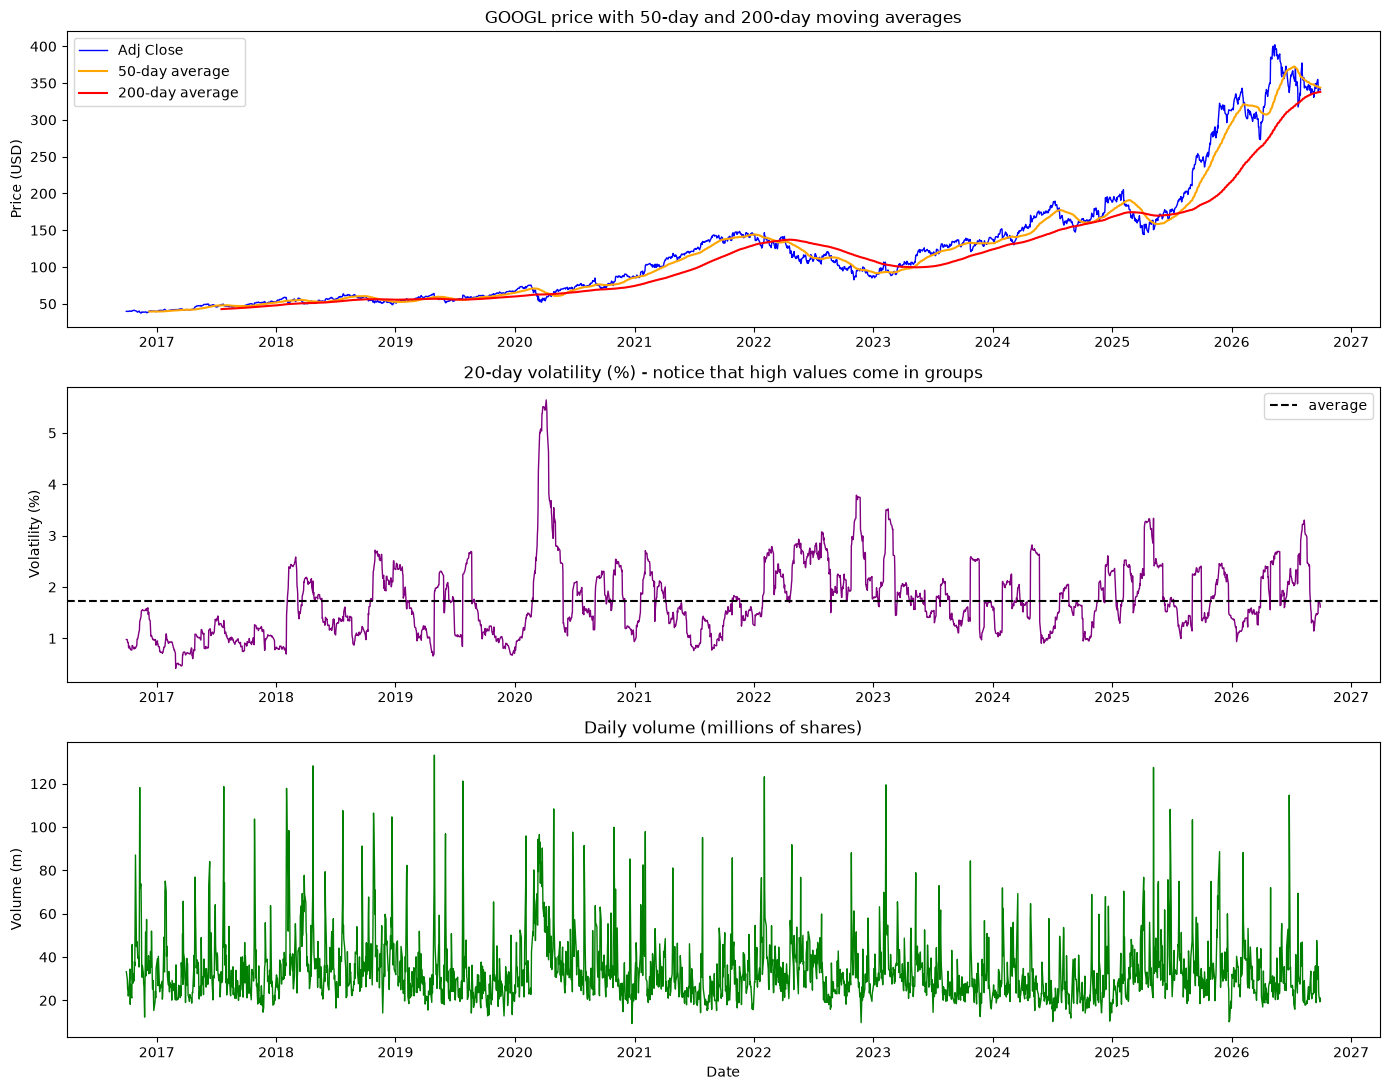

In [15]:
# Plot 1: price, volatility and volume
fig, ax = plt.subplots(3, 1, figsize=(14, 11))

# Top plot: the price with two moving averages
ax[0].plot(feat.index, feat['Adj Close'], color='blue', linewidth=1, label='Adj Close')
ax[0].plot(feat.index, feat['Adj Close'].rolling(50).mean(), color='orange', label='50-day average')
ax[0].plot(feat.index, feat['Adj Close'].rolling(200).mean(), color='red', label='200-day average')
ax[0].set_title('GOOGL price with 50-day and 200-day moving averages')
ax[0].set_ylabel('Price (USD)')
ax[0].legend()

# Middle plot: the 20-day volatility
ax[1].plot(feat.index, feat['Volatility_20'], color='purple', linewidth=1)
ax[1].axhline(feat['Volatility_20'].mean(), color='black', linestyle='--', label='average')
ax[1].set_title('20-day volatility (%) - notice that high values come in groups')
ax[1].set_ylabel('Volatility (%)')
ax[1].legend()

# Bottom plot: the volume
ax[2].plot(feat.index, feat['Volume'] / 1000000, color='green', linewidth=1)
ax[2].set_title('Daily volume (millions of shares)')
ax[2].set_ylabel('Volume (m)')
ax[2].set_xlabel('Date')

plt.tight_layout()
plt.show()

**Trend.** GOOGL went from \$39.82 to \$340.92 in ten years, a **total rise of 756%**, which is **23.96% per
year** (we calculate this properly in §8.9). The price clearly **trends upwards**, so it is

**Non-stationary**. This already tells us that we will need differencing (`d` of at least 1) before we can
use ARIMA.

**Volatility comes in groups — this is the key point for the clustering.** The middle plot shows that
20-day volatility is not constant. It goes from **0.42% up to 5.64%**, with an average of **1.73%**, and the
high values arrive in *groups* rather than randomly. The big spikes are the 2018 selloff, the COVID crash of
early 2020, the 2022 fall and an episode in April 2026. This grouping is what makes "market regime" a real
idea, and it is the reason clustering is worth doing.

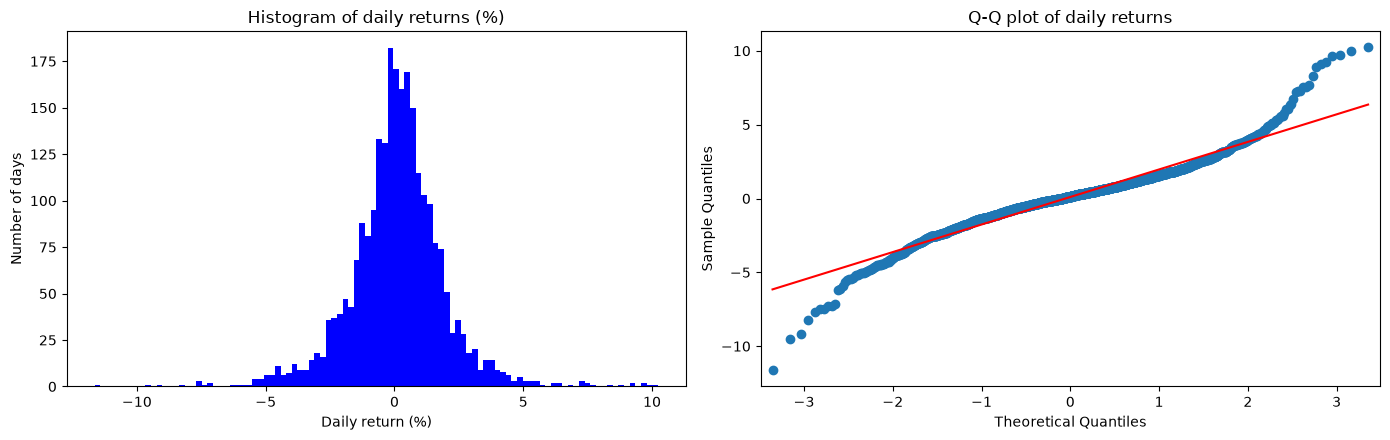

Smallest daily return: -11.63 %
Largest daily return : 10.22 %
Standard deviation   : 1.87 %
Skewness: 0.05   (0 means symmetric)
Kurtosis: 4.309   (0 means normal tails, above 0 means fat tails)


In [ ]:
# Plot 2: are the daily returns normally distributed?
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))

# Histogram of the returns
# - Blue line: the daily adjusted closing price in USD.
# - Orange line: the 50-day moving average, a smoothed version of the price.
# - Red line: the 200-day moving average, smoother still.
ax[0].hist(feat['Return'], bins=100, color='blue')
ax[0].set_title('Histogram of daily returns (%)')
ax[0].set_xlabel('Daily return (%)')
ax[0].set_ylabel('Number of days')

# Q-Q plot: if the data is normal, the points sit on the red line (Tutorial 6(a))
sm.qqplot(feat['Return'], line='s', ax=ax[1])
ax[1].set_title('Q-Q plot of daily returns')

plt.tight_layout()
plt.show()

print('Smallest daily return:', round(feat['Return'].min(), 2), '%')
print('Largest daily return :', round(feat['Return'].max(), 2), '%')
print('Standard deviation   :', round(feat['Return'].std(), 2), '%')
print('Skewness:', round(feat['Return'].skew(), 3), '  (0 means symmetric)')
print('Kurtosis:', round(feat['Return'].kurtosis(), 3), '  (0 means normal tails, above 0 means fat tails)')

**The returns are not normal.** The histogram has a much taller peak than a normal curve would, and in the
Q-Q plot the points bend away from the red line at both ends. This means the data has **fat tails**: very
big moves happen more often than a normal distribution allows. The returns range from **−11.63% to
+10.22%** even though the standard deviation is only **1.87%**, and the kurtosis is **4.31**.

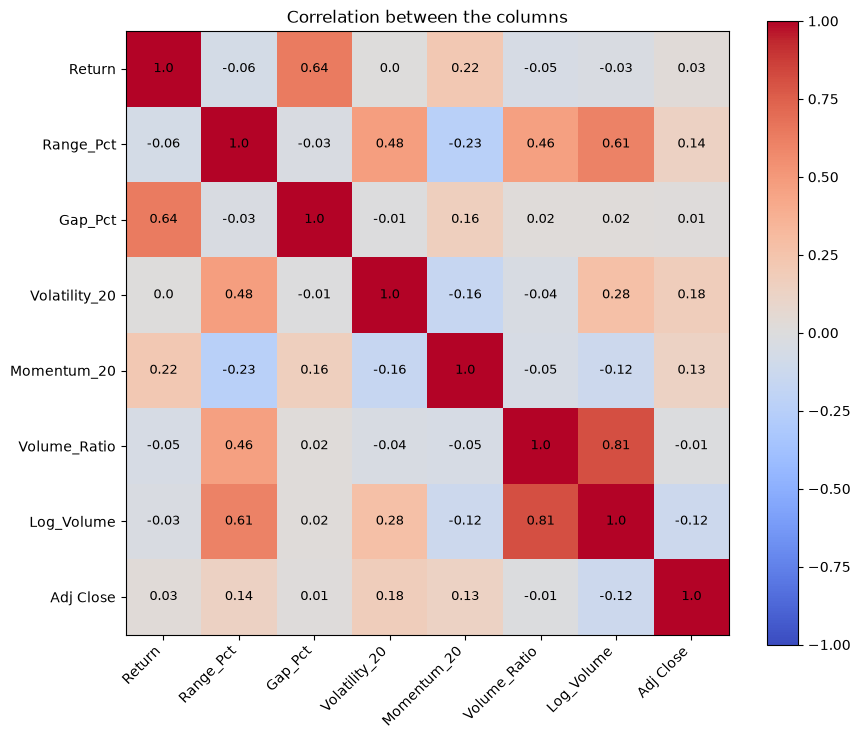

In [12]:
# Plot 3: correlation between the new columns
corr_cols = ['Return', 'Range_Pct', 'Gap_Pct', 'Volatility_20',
             'Momentum_20', 'Volume_Ratio', 'Log_Volume', 'Adj Close']
corr = feat[corr_cols].corr()

plt.figure(figsize=(9, 7.5))
plt.imshow(corr, cmap='coolwarm', vmin=-1, vmax=1)
plt.colorbar()
plt.xticks(range(len(corr_cols)), corr_cols, rotation=45, ha='right')
plt.yticks(range(len(corr_cols)), corr_cols)

# Write the correlation number inside every box
for i in range(len(corr_cols)):
    for j in range(len(corr_cols)):
        plt.text(j, i, round(corr.iloc[i, j], 2), ha='center', va='center', fontsize=9)

plt.title('Correlation between the columns')
plt.tight_layout()
plt.show()

**The correlation plot shows our new columns were a good idea.** `Range_Pct` and `Volatility_20` are
positively correlated because both measure volatility, but over different lengths of time, so we keep both.
`Return` has almost no correlation with `Volatility_20`, which means **direction** and **size** are two
separate pieces of information, so the clustering needs both. Most importantly, `Adj Close` has almost no
correlation with any of the new columns, which proves that our percentage columns describe *behaviour* and
not the price level or the date — exactly what we wanted.